In [3]:
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict
from langgraph.checkpoint.memory import InMemorySaver

In [2]:
load_dotenv()

llm = ChatOpenAI(model = 'gpt-4o-mini')

In [4]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [5]:
def gen_joke(state: JokeState):

    joke_topic = state['topic']
    prompt = f'''Generate a small witty joke on the topic {joke_topic}'''

    joke = llm.invoke(prompt).content

    return {'joke': joke}

In [6]:
def expl_joke(state: JokeState):

    joke = state['joke']
    prompt = f'''Write an explanation of the following joke: \n {joke}'''

    explanation = llm.invoke(prompt).content

    return {'explanation': explanation}

In [7]:
graph = StateGraph(JokeState)

graph.add_node('gen_joke', gen_joke)
graph.add_node('expl_joke', expl_joke)

graph.add_edge(START, 'gen_joke')
graph.add_edge('gen_joke', 'expl_joke')
graph.add_edge('expl_joke', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

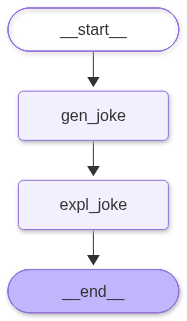

In [8]:
workflow

In [9]:
config_1 = {'configurable': {'thread_id': '1'}}

workflow.invoke({'topic': 'pizza'}, config=config_1)

{'topic': 'pizza',
 'joke': 'Why did the pizza maker go broke?  \n\nBecause he just couldn’t make enough dough! 🍕',
 'explanation': 'This joke plays on a clever double meaning of the word "dough." \n\nIn one sense, "dough" is the mixture of flour and water (along with other ingredients) that is used to make pizza crust. This is a direct reference to the pizza maker\'s profession, as making pizza involves making dough.\n\nOn the other hand, "dough" is also a slang term for money. The phrase "make enough dough" is commonly used to refer to earning sufficient income.\n\nThe humor arises from the clever pun that connects the two meanings. The pizza maker went broke because he was unable to produce enough pizza (and therefore enough dough in the culinary sense), which ultimately led to him not making enough money (dough in the financial sense). This play on words creates a lighthearted and amusing punchline.'}

In [10]:
workflow.get_state(config_1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza maker go broke?  \n\nBecause he just couldn’t make enough dough! 🍕', 'explanation': 'This joke plays on a clever double meaning of the word "dough." \n\nIn one sense, "dough" is the mixture of flour and water (along with other ingredients) that is used to make pizza crust. This is a direct reference to the pizza maker\'s profession, as making pizza involves making dough.\n\nOn the other hand, "dough" is also a slang term for money. The phrase "make enough dough" is commonly used to refer to earning sufficient income.\n\nThe humor arises from the clever pun that connects the two meanings. The pizza maker went broke because he was unable to produce enough pizza (and therefore enough dough in the culinary sense), which ultimately led to him not making enough money (dough in the financial sense). This play on words creates a lighthearted and amusing punchline.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoi

In [11]:
list(workflow.get_state_history(config_1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza maker go broke?  \n\nBecause he just couldn’t make enough dough! 🍕', 'explanation': 'This joke plays on a clever double meaning of the word "dough." \n\nIn one sense, "dough" is the mixture of flour and water (along with other ingredients) that is used to make pizza crust. This is a direct reference to the pizza maker\'s profession, as making pizza involves making dough.\n\nOn the other hand, "dough" is also a slang term for money. The phrase "make enough dough" is commonly used to refer to earning sufficient income.\n\nThe humor arises from the clever pun that connects the two meanings. The pizza maker went broke because he was unable to produce enough pizza (and therefore enough dough in the culinary sense), which ultimately led to him not making enough money (dough in the financial sense). This play on words creates a lighthearted and amusing punchline.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpo

In [12]:
config_2 = {'configurable': {'thread_id': '1'}}

workflow.invoke({'topic': 'pasta'}, config=config_2)

{'topic': 'pasta',
 'joke': "Why didn't the ravioli get invited to hang out?\n\nBecause it was too wrapped up in itself! 🍝",
 'explanation': 'This joke relies on a play on words and a bit of personification to create humor. \n\n1. **Food Reference**: The joke begins with ravioli, which are pasta pockets typically filled with ingredients. The humor arises from the fact that ravioli are literally wrapped up in pasta dough. \n\n2. **Figurative Language**: The phrase "too wrapped up in itself" is a common idiom that means someone is overly focused on their own concerns or issues, to the point of being oblivious to others or lacking social awareness. \n\n3. **Dual Meaning**: The joke cleverly combines the literal and figurative meanings. The ravioli is "wrapped up" physically (being a type of pasta) and metaphorically (not participating in social activities due to being self-absorbed).\n\n4. **Punchline**: The punchline delivers a twist by giving an inanimate object (the ravioli) human-like

In [13]:
workflow.get_state(config_2)

StateSnapshot(values={'topic': 'pasta', 'joke': "Why didn't the ravioli get invited to hang out?\n\nBecause it was too wrapped up in itself! 🍝", 'explanation': 'This joke relies on a play on words and a bit of personification to create humor. \n\n1. **Food Reference**: The joke begins with ravioli, which are pasta pockets typically filled with ingredients. The humor arises from the fact that ravioli are literally wrapped up in pasta dough. \n\n2. **Figurative Language**: The phrase "too wrapped up in itself" is a common idiom that means someone is overly focused on their own concerns or issues, to the point of being oblivious to others or lacking social awareness. \n\n3. **Dual Meaning**: The joke cleverly combines the literal and figurative meanings. The ravioli is "wrapped up" physically (being a type of pasta) and metaphorically (not participating in social activities due to being self-absorbed).\n\n4. **Punchline**: The punchline delivers a twist by giving an inanimate object (the 

In [14]:
list(workflow.get_state_history(config_2))

[StateSnapshot(values={'topic': 'pasta', 'joke': "Why didn't the ravioli get invited to hang out?\n\nBecause it was too wrapped up in itself! 🍝", 'explanation': 'This joke relies on a play on words and a bit of personification to create humor. \n\n1. **Food Reference**: The joke begins with ravioli, which are pasta pockets typically filled with ingredients. The humor arises from the fact that ravioli are literally wrapped up in pasta dough. \n\n2. **Figurative Language**: The phrase "too wrapped up in itself" is a common idiom that means someone is overly focused on their own concerns or issues, to the point of being oblivious to others or lacking social awareness. \n\n3. **Dual Meaning**: The joke cleverly combines the literal and figurative meanings. The ravioli is "wrapped up" physically (being a type of pasta) and metaphorically (not participating in social activities due to being self-absorbed).\n\n4. **Punchline**: The punchline delivers a twist by giving an inanimate object (the